## 1. 문제 정의
#### 원인탐색 및 그룹비교
- 연식이 낮을수록 매물가가 높은가?
- 평수가 높을수록 매물가가 높은가?
#### 예측
- 연식과 평수로 부동산 가격을 예측할 수 있는가?
#### 의사 결정
- 어떤 매물을 매입해야 이익을 볼 수 있는가?
---
## 2. 데이터 이해
#### 데이터 크기 : col:4, raw:1- 의 데이터프레임
#### 관측 단위 : 행 하나가 매물 한개의 정보를 담음
#### 자료형 : ID(명목형), size(수치형 - 이산), year(수치형 - 이산), price(수치형 - 연속)
#### 변수 의미 : ID(식별자), size(평수), year(연식), price(가격)
#### 타깃 변수 : price의 값을 예측하는 것이 목적
- 독립 변수 : size, year
- 종속 변수 : price
#### 시간 구조 : 알 수 없음
---
## 3. 데이터 품질 진단
#### 결측치, 이상치, 중복, 값 범위 오류 : 없음
---
## 4. 데이터 전처리 : 필요없음
---
## 5. 탐색적 데이터 분석 (EDA)

연식과 가격의 상관관계 - 산점도
평수와 가격의 상관관계 - 산점도
ID별 가격 비교 - 막대그래프
---
## 6. 통계적 검증
1. 가설설정
- 귀무가설: 평수와 매매가는 관련이 없다.

- 대립가설: 평수와 매매가는 관련이 있다.

2. 통계 검정 방법 선택
- 피어슨 상관분석: 평수와 가격의 선형 상관관계 확인

- 단순 선형회귀: 평수 변화에 따른 가격 변화 추정

- 다중 선형회귀: 평수와 연식을 함께 사용하여 가격 설명 및 예측
---
## 7. 모델링 및 평가
---
## 8. 결과 해석

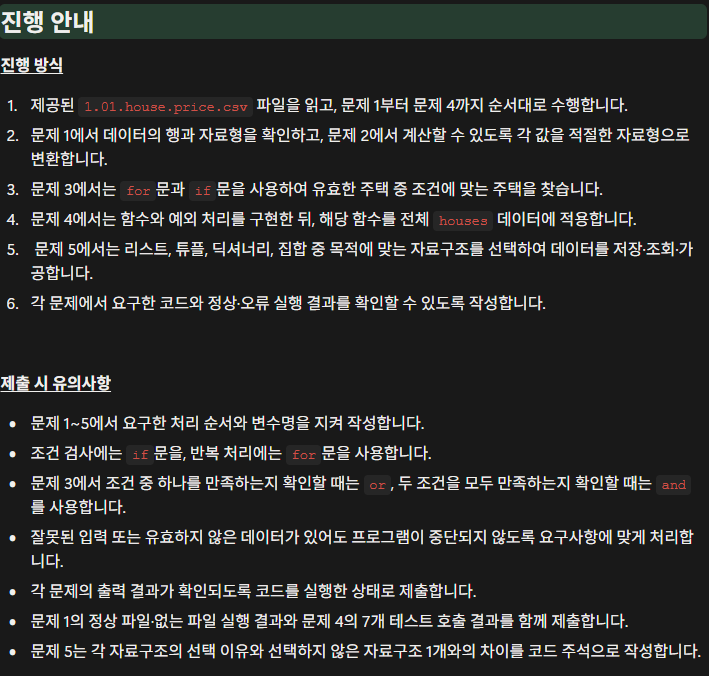
---
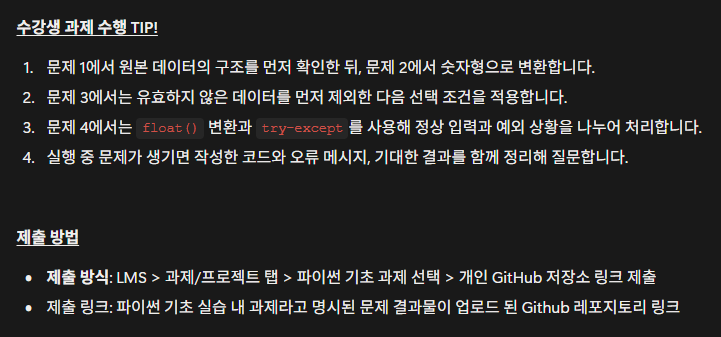

## 1-1. CSV 파일 읽기

In [48]:
# ① Python 코드에서 1.01.house.price.csv 파일을 읽습니다.
# ② 읽은 행을 df_house 데이터프레임에 저장합니다.
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

df_house = pd.read_csv('/content/1.01.house.price.csv')

df_house

,ID,size,year,price
0,1,34,5,5.0
1,2,25,5,2.5
2,3,30,2,4.0
3,4,38,20,3.0
4,5,44,12,3.3
5,6,48,18,4.2
6,7,52,22,4.6
7,8,60,19,6.0
8,9,34,18,3.0
9,10,34,22,2.9


In [49]:
# ③ 첫 번째 행과 전체 데이터 행 수를 출력합니다.
raw1 = df_house.head(1)
print(f"첫번째 행 출력⬇️")
display(raw1)
print(f"전체 데이터 행 수: {len(df_house)}")

첫번째 행 출력⬇️


,ID,size,year,price
0,1,34,5,5.0


전체 데이터 행 수: 10


In [50]:
# ④ 첫 번째 행의 price 값이 어떤 자료형인지 출력합니다.
print(f"price 열의 Pandas 자료형: {raw1['price'].dtype}")
print(f"실제 값의 Python 자료형: {type(raw1['price'].iloc[0])}")

price 열의 Pandas 자료형: float64
실제 값의 Python 자료형: <class 'numpy.float64'>


In [51]:
# ⑤ 파일이 존재하지 않으면 FileNotFoundError를 처리하여 “파일명과 업로드 여부를 확인하세요.”를 출력합니다.
# ⑥ 파일 읽기에 성공한 경우에만 이후 데이터 확인을 수행하고, 정상 파일명과 존재하지 않는 파일명을 각각 실행하여 결과를 확인합니다. (정상 처리 결과와 오류 처리 결과 제출)

file_path = '/content/1.01.house.price.csv'

try:
    df_house = pd.read_csv(file_path)
    print("🎉 파일 읽기 성공!")

    print(f"데이터 크기 (행 수): {len(df_house)}")
    display(df_house.head(2))

except FileNotFoundError:
    # 파일이 없을 때 실행될 코드
    print("파일명과 업로드 여부를 확인하세요.")

🎉 파일 읽기 성공!
데이터 크기 (행 수): 10


,ID,size,year,price
0,1,34,5,5.0
1,2,25,5,2.5


In [52]:
file_path = '/content/없는파일.csv'

try:
    df_house = pd.read_csv(file_path)
    print("🎉 파일 읽기 성공!")

    print(f"데이터 크기 (행 수): {len(df_house)}")
    display(df_house.head(2))

except FileNotFoundError:
    # 파일이 없을 때 실행될 코드
    print("파일명과 업로드 여부를 확인하세요.")

파일명과 업로드 여부를 확인하세요.


## 1-2. 문자열을 숫자로 변환하기

In [53]:
'''
| 열 이름 | 변환할 자료형 |
| --- | --- |
| `ID` | `int` |
| `size` | `int` |
| `year` | `int` |
| `price` | `float` |
'''
# ① 빈 리스트 houses를 생성합니다.
houses = []
success_count = 0
error_count = 0

# ② 반복문을 사용하여 각 행을 순회합니다.
# ③ 각 행의 값을 아래 자료형으로 변환하여 houses에 저장합니다.
for index, row in df_house.iterrows():
    try:
        house = {
            "ID": int(row["ID"]),
            "size": int(row["size"]),
            "year": int(row["year"]),
            "price": float(row["price"])
        }
        houses.append(house)
        success_count += 1
    # ④ 필수 값이 누락되었거나 숫자로 변환할 수 없는 행은 houses에 저장하지 않고, 행 위치와 제외 사유를 출력합니다.
    except (ValueError, TypeError) as e:
        print(f"행 {index} 제외 사유: {e}")
        error_count += 1
    # ⑤ 한 행에서 변환 오류가 발생해도 반복문을 중단하지 않고 다음 행을 계속 처리한 뒤, 정상 저장 행 수와 제외 행 수를 출력합니다.
print(f"정상 저장 행 수: {success_count}, 제외 행 수: {error_count}")

정상 저장 행 수: 10, 제외 행 수: 0


In [57]:
import copy
import numpy as np
# ① 원본 houses를 유지한 채 houses_test를 복사하고, 아래 테스트 데이터를 추가합니다.
houses_test = copy.deepcopy(houses)
houses_test.extend([
    {"ID": 101, "year": 5, "price": 3},
    {"ID": 102, "size": 35, "year": 5, "price": None},
    {"ID": 103, "size": "오류", "year": 5, "price": 3},
    {"ID": 104, "size": 35, "year": 5, "price": 3}
])

# ② houses_test를 for문으로 반복 처리하고, 조건을 비교하기 전에 size·price 키와 값을 검사합니다.
#    키 누락, None·결측값, 숫자 변환 불가 값은 각각 제외 사유를 출력하고 건너뜁니다.
'''
- size 또는 price 키가 없거나, 값이 None 또는 결측값이면 제외 사유를 출력하고 해당 주택을 건너뛰기
- 숫자로 변환할 수 없는 값도 제외 사유를 출력하고 건너뛰기. 숫자 형태의 문자열은 숫자로 변환하여 검사해도 됨
- 잘못된 데이터가 있더라도 나머지 주택에 대한 검사와 필터링은 끝까지 수행
'''
selected = []
for house in houses_test:
    # 만약 원본 데이터가 리스트 형태로 들어있을 경우 딕셔너리로 호환 변환
    if isinstance(house, list) and len(house) == 4:
        house = {"ID": house[0], "size": house[1], "year": house[2], "price": house[3]}

    # 키 누락 검사
    if not isinstance(house, dict) or "size" not in house or "price" not in house:
        print(f"ID {house.get('ID') if isinstance(house, dict) else 'Unknown'} 제외: 필수 키(size 또는 price) 누락")
        continue

    # ③ 조건을 비교하기 전에 size와 price가 존재하고 사용할 수 있는 값인지 검사하세요.
    # None 결측치 검사
    if house["size"] is None or house["price"] is None:
        print(f"ID {house['ID']} 제외: None(결측치) 포함")
        continue

    # 숫자 변환 불가 검사
    try:
        s = float(house["size"])
        p = float(house["price"])
    except (ValueError, TypeError):
        print(f"ID {house['ID']} 제외: 숫자로 변환 불가한 데이터")
        continue

    # np.isfinite()를 활용해 NaN과 무한대(inf) 결측치 추가 검사
    if not np.isfinite(s) or not np.isfinite(p):
        print(f"ID {house['ID']} 제외: 유효하지 않은 숫자값(NaN 또는 무한대) 포함")
        continue

    # ④ size가 0 이하이거나 price가 음수인 주택은 제외합니다.
    # 비정상 값 제외 (or, continue 사용)
    # ③ 유효하지 않은 주택을 제외할 때 or와 continue를 사용합니다.
    if s <= 0 or p < 0:
        print(f"ID {house['ID']} 제외: size가 0 이하이거나 price가 음수")
        continue

    # ④ 아래 두 조건을 모두 만족하는 주택을 selected 리스트에 저장합니다.
    '''
    - `size`가 30 이상
    - `price`가 4 이하
    '''
    # 조건에 맞는 주택 필터링 (and 사용)
    if s >= 30 and p <= 4:
        selected.append(house)

print("-" * 20)
for s in selected:
    # ⑥ 선택한 주택의 ID를 하나씩 출력합니다.
    print(f"선택된 주택 ID: {s['ID']}")
# ⑦ 선택한 주택의 전체 건수를 출력합니다.
print(f"선택된 주택 전체 건수: {len(selected)}")

ID 101 제외: 필수 키(size 또는 price) 누락
ID 102 제외: None(결측치) 포함
ID 103 제외: 숫자로 변환 불가한 데이터
--------------------
선택된 주택 ID: 3
선택된 주택 ID: 4
선택된 주택 ID: 5
선택된 주택 ID: 9
선택된 주택 ID: 10
선택된 주택 ID: 104
선택된 주택 전체 건수: 6


In [55]:
# ① 가격을 크기로 나눈 값을 계산하는 아래 함수를 작성합니다.
def unit_price(price, size):
    # ⑦ 잘못된 입력이 있어도 프로그램이 중단되지 않도록 처리합니다.
    try:
        # ② 숫자 또는 숫자 형태의 문자열을 입력받도록 작성합니다.
        p = float(price)
        s = float(size)
    # ⑤ 숫자로 변환할 수 없는 문자열을 입력하여 ValueError가 발생하면, “값 오류: 숫자로
    #    변환할 수 없는 문자열입니다.”라는 안내 문구를 출력하고 None을 반환합니다.
    except ValueError:
        print("값 오류: 숫자로 변환할 수 없는 문자열입니다.")
        return None
    # ⑥ None 등 숫자로 변환할 수 없는 자료형을 입력하여 TypeError가 발생하면,
    #   “자료형 오류: 숫자 또는 숫자 형태의 문자열을 입력하세요.”라는 안내 문구를 출력하고 None을 반환합니다.
    except TypeError:
        print("자료형 오류: 숫자 또는 숫자 형태의 문자열을 입력하세요.")
        return None
    # ④ 크기가 0 이하이거나 가격이 음수이면 각각 원인을 알 수 있는 안내 문구를 출력하고 None을 반환합니다.
    if s <= 0:
        print("크기 오류: 크기는 0보다 커야 합니다.")
        return None
    if p < 0:
        print("가격 오류: 가격은 음수가 될 수 없습니다.")
        return None
    # ③ 정상 입력이면 가격 ÷ 크기를 반환합니다.
    return p / s

# ⑨ 아래 호출을 순서대로 실행하여 반환값과 안내 문구를 확인합니다.
print("[함수 테스트 결과]")
print(unit_price(4, 40))
print(unit_price("4", "40"))
print(unit_price(4, 0))
print(unit_price(-4, 40))
print(unit_price("오류", 40))
print(unit_price(None, 40))
print(unit_price(6, 30))

# ⑧ 작성한 함수를 전체 houses에 적용하여 주택 ID와 크기당 가격을 출력합니다.
print("\n[전체 houses 적용 결과]")
for h in houses:
    # 리스트 데이터가 섞여 있을 경우를 대비하여 딕셔너리로 변환 처리
    if isinstance(h, list) and len(h) == 4:
        h = {"ID": h[0], "size": h[1], "year": h[2], "price": h[3]}
    u_price = unit_price(h['price'], h['size'])
    print(f"ID {h['ID']}의 크기당 가격: {u_price}")

[함수 테스트 결과]
0.1
0.1
크기 오류: 크기는 0보다 커야 합니다.
None
가격 오류: 가격은 음수가 될 수 없습니다.
None
값 오류: 숫자로 변환할 수 없는 문자열입니다.
None
자료형 오류: 숫자 또는 숫자 형태의 문자열을 입력하세요.
None
0.2

[전체 houses 적용 결과]
ID 1의 크기당 가격: 0.14705882352941177
ID 2의 크기당 가격: 0.1
ID 3의 크기당 가격: 0.13333333333333333
ID 4의 크기당 가격: 0.07894736842105263
ID 5의 크기당 가격: 0.075
ID 6의 크기당 가격: 0.08750000000000001
ID 7의 크기당 가격: 0.08846153846153845
ID 8의 크기당 가격: 0.1
ID 9의 크기당 가격: 0.08823529411764706
ID 10의 크기당 가격: 0.08529411764705883


In [56]:
'''
⑤ 각 작업에 리스트·튜플·딕셔너리·집합 중 적합한 자료구조를 선택하고,
선택 이유 및 선택하지 않은 자료구조 1개와의 차이를 코드 주석으로 작성합니다.
순서 유지, 중복 허용 여부, 키를 통한 조회,
변경 가능 여부 중 해당 작업의 판단 근거를 포함합니다.
'''

# ① houses를 활용하여 전체 주택 ID를 원래 순서대로 저장하고 출력합니다.
# 1. 리스트: 전체 주택 ID를 순서대로 저장
# 선택 이유: 데이터의 입력 순서가 유지되고 순차적 반복(인덱싱)이 용이하기 때문.
# 대안(집합)과의 차이: 집합(Set)은 순서가 없고 중복을 없애버리기 때문에 원본 데이터의 순서를 유지하려면 리스트가 적합합니다.
id_list = [h[0] if isinstance(h, list) else h["ID"] for h in houses]
print(f"ID 목록: {id_list}")

# ② 주택의 year 값을 중복 없이 저장하고 출력합니다.
# 2. 집합: year 값을 중복 없이 저장
# 선택 이유: 집합(Set) 자료형의 고유 특성인 '중복 허용 안 함'을 활용하기 위함.
# 대안(리스트)과의 차이: 리스트는 중복된 값을 그대로 저장하지만, 집합은 자동으로 중복을 제거해 줍니다.
year_set = {h[2] if isinstance(h, list) else h["year"] for h in houses}
print(f"중복 없는 year: {year_set}")

# ③ 주택 ID로 가격을 조회할 수 있도록 저장하고, ID 3의 가격을 출력합니다.
# 3. 딕셔너리: 주택 ID를 키(Key)로, 가격을 값(Value)으로 저장
# 선택 이유: 특정 ID에 대한 데이터를 반복문 없이 단번에 검색(O(1))할 수 있기 때문.
# 대안(리스트)과의 차이: 리스트는 인덱스로만 접근할 수 있어 고유 ID 번호로 데이터를 바로 맵핑해 찾기 어렵습니다.
price_dict = {h[0] if isinstance(h, list) else h["ID"]: h[3] if isinstance(h, list) else h["price"] for h in houses}
print(f"ID 3의 가격: {price_dict.get(3, '존재하지 않음')}")

# ④ 최소 크기 30과 최대 가격 4를 각각 하나의 원소로 갖는 묶음으로 저장하세요. 생성한 뒤 원소를 추가/삭제하거나 다른 값으로 교체할 수 없는 자료구조를 선택하고, 선택 이유를 설명하세요.
# 4. 튜플: 최소 크기(30)와 최대 가격(4) 조건 묶음
# 선택 이유: 생성된 이후 내부 원소를 변경, 추가, 삭제할 수 없는 불변성(Immutable) 특성을 가져, 검색 기준값이 의도치 않게 바뀌는 것을 방지합니다.
# 대안(리스트)과의 차이: 리스트는 .append(), 값 변경 등이 가능해 고정된 설정값을 저장할 땐 튜플이 더 안전합니다.
condition_tuple = (30, 4)
print(f"불변 검색 조건: {condition_tuple}")

ID 목록: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
중복 없는 year: {2, 5, 12, 18, 19, 20, 22}
ID 3의 가격: 4.0
불변 검색 조건: (30, 4)
